In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [87]:
X,y_true= make_blobs(n_samples=500, centers=3, cluster_std=0.40,
                  random_state=0)

In [88]:
df=pd.DataFrame(X,columns=['Feature_1',"Feature_2"])

In [89]:
df

,Feature_1,Feature_2
0,1.027035,4.464583
1,-1.689281,3.207630
2,-1.729911,2.497130
3,1.232323,3.657005
4,0.201758,4.379299
...,...,...
495,2.297316,1.255886
496,2.383396,1.441643
497,2.363830,1.309439
498,0.547969,4.725568


In [90]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(df)




In [91]:
intertia=[]
k_range=range(1,11) 

In [92]:
for k in k_range:
    Kmeans=KMeans(n_clusters=k, random_state=42)
    Kmeans.fit(X_scaled)
    intertia.append(Kmeans.inertia_)
    

In [93]:
intertia

[1000.0000000000002,
 356.5611223509547,
 67.07724957360949,
 58.208525201939665,
 50.58076308126188,
 43.0350372812085,
 37.787173841022216,
 33.73332731274617,
 31.939168662758114,
 29.17771559597374]

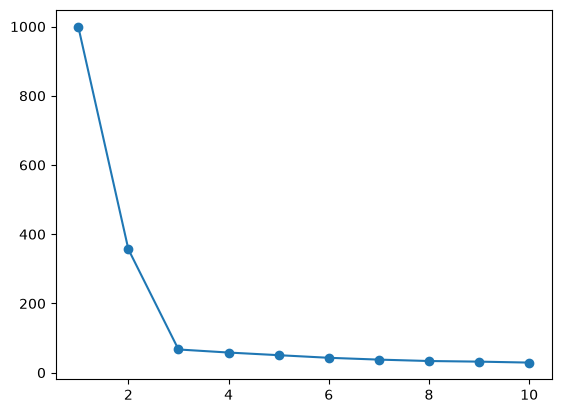

In [94]:
plt.plot(k_range, intertia, marker='o')  # elbow methods

In [95]:
Kmeans_final=KMeans(n_clusters=3 , random_state=42)

In [96]:
cluster_label = Kmeans_final.fit_predict(X_scaled)

In [97]:
df['cluster']=cluster_label

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

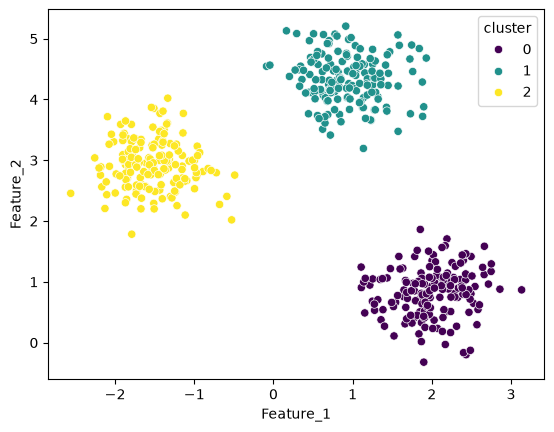

In [98]:
sns.scatterplot(x=df['Feature_1'],
                y=df['Feature_2'],
                hue=df['cluster'],
                palette='viridis')

# DBSCAN

In [108]:
from sklearn.datasets import make_moons

In [109]:
X, y = make_moons(n_samples=500, noise=0.05, random_state=42)

In [110]:
from sklearn.cluster import KMeans,DBSCAN

In [111]:
df=pd.DataFrame(X,columns=['feature_1','feature_2'])

In [112]:
df

,feature_1,feature_2
0,0.830586,-0.447733
1,0.701678,0.816918
2,1.022080,-0.492571
3,-0.316765,0.953438
4,0.293226,1.057185
...,...,...
495,0.239754,0.985462
496,0.072145,0.184834
497,0.590273,-0.365577
498,1.619465,-0.283658


In [113]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(df)

kmeans


In [ ]:
# kmeans

Kmeans_final=KMeans(n_clusters=3 , random_state=42)
Kmeans_label = Kmeans_final.fit_predict(X_scaled)

In [115]:
df['kmeans_cluster']=Kmeans_label

<Axes: xlabel='feature_1', ylabel='feature_2'>

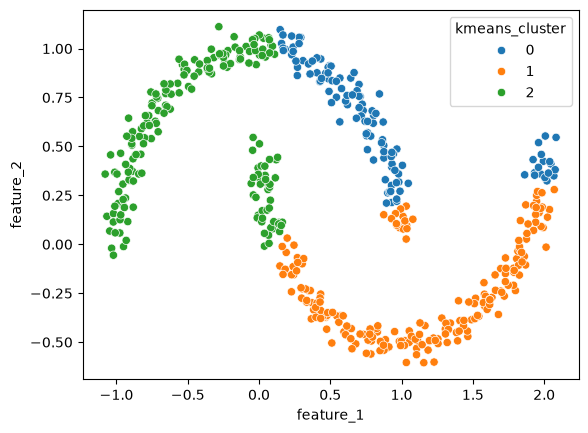

In [116]:
sns.scatterplot(x=df['feature_1'],y=df['feature_2'],hue=df['kmeans_cluster'],
                palette='tab10')

# DBSCAN

In [118]:
dbscan=DBSCAN(eps=0.3,min_samples=5)
dbscan_labels=dbscan.fit_predict(X_scaled)

In [119]:
df['dbscan_cluster']=dbscan_labels

<Axes: xlabel='feature_1', ylabel='feature_2'>

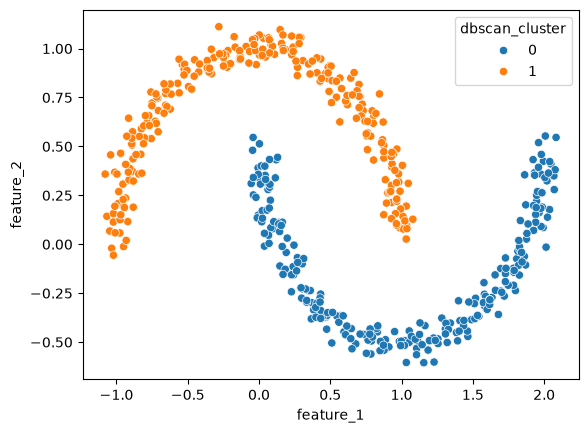

In [120]:
sns.scatterplot(x=df['feature_1'],y=df['feature_2'],hue=df['dbscan_cluster'],
                palette='tab10')